In [1]:
## Import neccesary Libraries
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from sklearn.model_selection import train_test_split

In [2]:
# Load the california housing dataset
housing=fetch_california_housing(as_frame=True)

In [3]:
## create df from dataset
df=housing.frame

In [4]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [6]:
#Features (independent variables) and target (dependent variable)
X=df.drop('MedHouseVal', axis=1)
y=df['MedHouseVal']

In [7]:
X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [8]:
y

,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422
...,...
20635,0.781
20636,0.771
20637,0.923
20638,0.847


In [9]:
## split the datset into training and testing
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [11]:
## Train linear regression model
model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [12]:
# make prediction on test set
y_pred=model.predict(X_test)

In [31]:
print(f"intercept{model.intercept_}")
print(f"coefficient{model.coef_}")


intercept-37.02327770606409
coefficient[ 4.48674910e-01  9.72425752e-03 -1.23323343e-01  7.83144907e-01
 -2.02962058e-06 -3.52631849e-03 -4.19792487e-01 -4.33708065e-01]


In [32]:
coef_df=pd.DataFrame(model.coef_,X.columns,columns=['Coefficient'])
coef_df

,Coefficient
MedInc,0.448675
HouseAge,0.009724
AveRooms,-0.123323
AveBedrms,0.783145
Population,-0.000002
AveOccup,-0.003526
Latitude,-0.419792
Longitude,-0.433708


In [33]:
## test the model with new data
new_data=pd.DataFrame(
    {'MedInc':5,
    'HouseAge':40,
    'AveRooms':5,
    'AveBedrms':3,
    'Population':5000,
    'AveOccup':2,
    'Latitude':[37.88],
    'Longitude':[-122.23]
})

predicted_price=model.predict(new_data)
print(predicted_price)

[4.4350818]


In [34]:
# Import visualization library
import matplotlib.pyplot as plt

In [35]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Dataset information
print("\nDataset Information:")
df.info()

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Records:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [36]:
# Display dataset details
print("Dataset Name: California Housing Dataset")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nTarget Variable: MedHouseVal")
print("Input Features:", X.columns.tolist())

Dataset Name: California Housing Dataset
Number of Rows: 20640
Number of Columns: 9

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Target Variable: MedHouseVal
Input Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


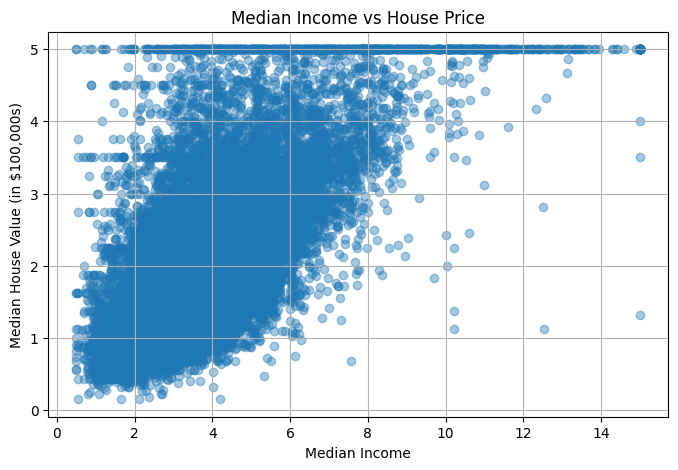

In [37]:
# Scatter plot: Median Income vs House Price

plt.figure(figsize=(8, 5))

plt.scatter(df['MedInc'], df['MedHouseVal'], alpha=0.4)

plt.title("Median Income vs House Price")
plt.xlabel("Median Income")
plt.ylabel("Median House Value (in $100,000s)")

plt.grid(True)
plt.show()

The scatter plot shows a generally positive relationship between median income and house prices. As median income increases, median house value also tends to increase. However, the points are scattered, indicating that other factors also affect house prices. This relationship does not prove causation.

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [39]:
# Display training and testing data details

print("Total observations:", len(df))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining data percentage:",
      (len(X_train) / len(df)) * 100, "%")

print("Testing data percentage:",
      (len(X_test) / len(df)) * 100, "%")

Total observations: 20640
Training observations: 16512
Testing observations: 4128

Training data percentage: 80.0 %
Testing data percentage: 20.0 %


The dataset is divided into 80% training data and 20% testing data. The training data is used to train the Linear Regression model, while the testing data is used to evaluate its performance on unseen observations. The testing data is not used during model training.

In [40]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, root_mean_squared_error

In [41]:
# Evaluate the model

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mse)

print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Squared Error (MSE): 0.5558915986952444
Mean Absolute Error (MAE): 0.5332001304956553
Root Mean Squared Error (RMSE): 0.7455813830127764
R2 Score: 0.5757877060324508


- MAE: It represents the average absolute difference between actual and predicted house prices.
- MSE: It calculates the average of squared prediction errors. Larger errors receive more penalty.
- RMSE: It is the square root of MSE and is expressed in the same units as the target variable.
- R² Score: It indicates how much variation in house prices is explained by the model. An R² score of 0.5758 means the model explains approximately 57.58% of the variation in the test data.
Note: The target MedHouseVal is measured in units of $100,000. Therefore, RMSE of approximately 0.7456 represents around $74,560.

In [42]:
# Compare actual and predicted house prices

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print("Actual vs Predicted House Prices:")
display(comparison.head(10))

Actual vs Predicted House Prices:


,Actual Price,Predicted Price
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746
9,4.46600,3.915615


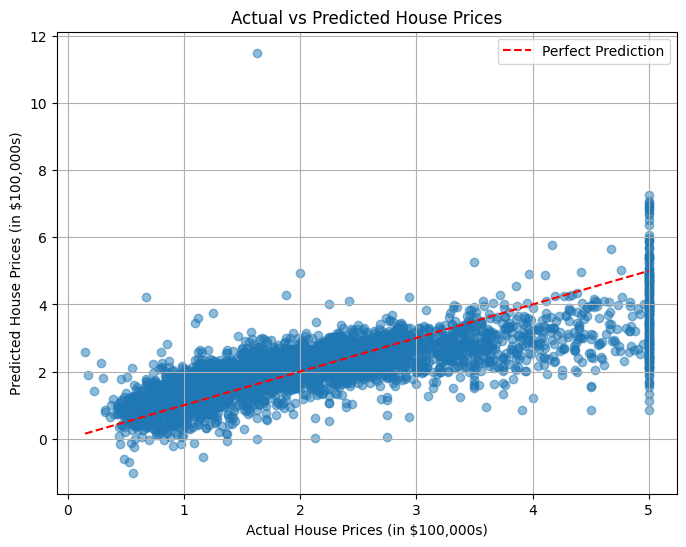

In [43]:
# Actual vs Predicted Price Visualization

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Reference line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual House Prices (in $100,000s)")
plt.ylabel("Predicted House Prices (in $100,000s)")
plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.grid(True)
plt.show()

In [44]:
# Display Linear Regression equation

print("Intercept:", model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

# Display the model equation
equation = f"MedHouseVal = {model.intercept_:.4f}"

for feature, coefficient in zip(X.columns, model.coef_):
    equation += f" + ({coefficient:.4f} × {feature})"

print("\nLinear Regression Equation:")
print(equation)

Intercept: -37.02327770606409

Coefficients:
MedInc : 0.44867490966571666
HouseAge : 0.009724257517904806
AveRooms : -0.12332334282795815
AveBedrms : 0.7831449067929722
Population : -2.029620580100075e-06
AveOccup : -0.003526318487134238
Latitude : -0.4197924865883604
Longitude : -0.433708064963987

Linear Regression Equation:
MedHouseVal = -37.0233 + (0.4487 × MedInc) + (0.0097 × HouseAge) + (-0.1233 × AveRooms) + (0.7831 × AveBedrms) + (-0.0000 × Population) + (-0.0035 × AveOccup) + (-0.4198 × Latitude) + (-0.4337 × Longitude)


In [45]:
predicted_price = model.predict(new_data)
print(predicted_price)

[4.4350818]


In [46]:
# Convert predicted value into actual dollars

price_in_dollars = predicted_price[0] * 100000

print("Predicted House Value:", predicted_price[0])
print("Predicted House Price: $", round(price_in_dollars, 2))

Predicted House Value: 4.435081797926081
Predicted House Price: $ 443508.18
